**Initialization, unzipping of data,  supporting functions**


In [11]:
import sys; sys.path.insert(0, "."); sys.path.insert(1, "..") 
import ast
import matplotlib.pyplot as plt
import os
import train

# unzip data files (run only once)
if not os.path.isfile('../data/4.train'): 
    print("unzipping")
    !ls ../data/*
    !gunzip -k ../data/*

        


**Training the model for one epoch (5 loop)**

In [12]:
# you can change model parameters here, the rest are the default
my_params= {'reload_data':'amplitude:../data/5.train',
         'eval_data':'../data/5.test', 
         'eval_size':-1,
         'epoch_size':100000,
         'max_epoch': 1
         }


parser = train.get_parser()
params = parser.parse_args([])

# update model params with the ones selected abov
for k,v in my_params.items():
    setattr(params,k,v)
    

# check parameters and run the model
train.check_model_params(params)
train.main(params)




INFO - 11/13/26 14:40:53 - 0:06:33 - Rank 0/1, local_rank=0, is_master=True
INFO - 11/13/26 14:40:53 - 0:00:00 - ============ Initialized logger ============
INFO - 11/13/26 14:40:53 - 0:00:00 - activation: gelu
                                     amp: False
                                     architecture: encoder_decoder
                                     attention_dropout: 0
                                     base: 1000
                                     batch_size: 32
                                     batch_size_eval: 128
                                     beam_eval: False
                                     beam_length_penalty: 1
                                     beam_size: 1
                                     clip_grad_norm: 5
                                     command: /opt/anaconda3/lib/python3.13/site-packages/ipykernel_launcher.py -f /Users/francoischarton/Library/Jupyter/runtime/kernel-2677f3d8-f997-442e-a456-21a11ab04505.json --exp_id 2026_11_13_14_40_5

All results are dumped into debug/2026_11_13_14_40_53

total 191536
-rw-r--r--@ 1 francoischarton  staff  97727201 Nov 13 14:42 checkpoint.pth
-rw-r--r--@ 1 francoischarton  staff      1498 Nov 13 14:40 params.pkl
-rw-r--r--@ 1 francoischarton  staff    298199 Nov 13 14:43 train.log

checkpoint.pth constains the model weights
train.log the experiment log


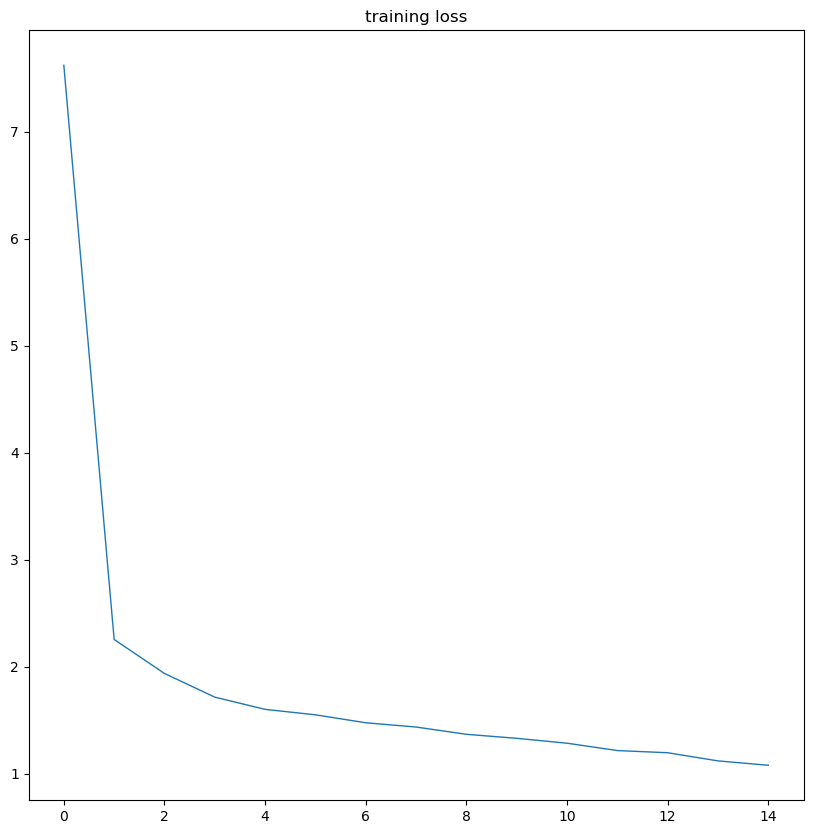


Final performances
epoch : 0
valid_AMPLITUDE_xe_loss : 1.0723342462760959
valid_AMPLITUDE_greedy_acc : 18.66
valid_AMPLITUDE_acc : 23.49
valid_AMPLITUDE_well_formed : 99.79
valid_AMPLITUDE_acc_-1 : 42.24314367580843
valid_AMPLITUDE_acc_1 : 5.572937035588581
valid_AMPLITUDE_avg_correct_sign : 0.5284
valid_AMPLITUDE_avg_correct_module : 0.3637


In [15]:
def read_losses(filename):
    res = []
    with open(filename, 'rt') as f:
        for line in f:
            if line.find("- LOSS") >=0:
                res.append(float(line.split(' ')[-4]))
    return res

def read_logs(filename):
    logs=[]
    with open(filename, 'rt') as f:
        for line in f:
            pos = line.find('__log__:')
            if pos >=0:
                dic = ast.literal_eval(line[pos+8:])
                logs.append(dic)
    return logs


path = params.dump_path

print(f'All results are dumped into {path}')
print()
!ls -l {path}

print()
print("checkpoint.pth constains the model weights")
print("train.log the experiment log")

logfile = os.path.join(path,"train.log")

loss = read_losses(logfile)

plt.plot(loss,linewidth=1)
plt.title("training loss")
plt.rcParams['figure.figsize'] = [10,10]
plt.show()


last_perf = read_logs(logfile)[-1]
print()
print("Final performances")
for s in last_perf:
    print(s, ":" , last_perf[s])
